# Figure 2 reconstruction from the SBML models

We started from the five local compressed BiGG SBML files and rebuild the reaction graphs. This notebook uses only those files and the published graph counts for comparison. We then keep the reaction set fixed and test what happens when currency metabolites can create links.

Run from the Data folder with NumPy, pandas, and Matplotlib installed. I use Python’s built-in XML and gzip modules to read the models. [Kim et al. (2019), Figure 2, Table 1, and Methods](https://doi.org/10.1186/s12859-019-2897-z).

## 1. Read the SBML model and decide which reactions to keep

The paper describes removing transport and exchange reactions and filtering currency metabolites. It does not give a complete list of the exclusions. We used explicit rules below so we can show where my reconstruction agrees with Table 1 and where it differs.

We excluded boundary reactions, biomass objectives, reactions with zero bounds in both directions, and reactions spanning multiple compartments as a proxy for transport. That proxy may also remove reactions that the authors retained. We kept metabolite IDs compartment-specific when linking reactions.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

# keep the notebooks with the input files, so the paths are relative to Data.
data_dir = Path.cwd() / "data"
models = ["iJO1366", "iYO844", "iAF987", "iYL1228", "iMM904"]
organisms = ["E. coli", "B. subtilis", "G. metallireducens",
             "K. pneumoniae", "S. cerevisiae"]
series = [("Total", "black", "o"), ("In", "tab:red", "s"),
          ("Out", "tab:blue", "^")]
published_results = pd.DataFrame(
    [[1251, 9099, -1.29, -1.32, -1.50],
     [748, 6489, -1.03, -1.10, -1.12],
     [900, 8049, -1.03, -1.14, -1.11],
     [1137, 8084, -1.21, -1.31, -1.47],
     [881, 10460, -0.99, -1.08, -1.16]],
    index=models, columns=["Nodes", "Arcs", "Total", "In", "Out"],
)

In [2]:
import gzip
import xml.etree.ElementTree as ET
from collections import defaultdict

fbc = "{http://www.sbml.org/sbml/level3/version1/fbc/version2}"

# The paper gives examples, so make my full approximation visible here.
# These are base BiGG IDs without their compartment suffixes.
currency_ids = {
    "atp", "adp", "amp", "gtp", "gdp", "gmp", "ctp", "cdp", "cmp",
    "utp", "udp", "ump", "nad", "nadh", "nadp", "nadph", "fad", "fadh2",
    "h2o", "h", "pi", "ppi", "co2",
}


def read_reactions(path):
    """Read allowed reaction directions from a local BiGG FBC v2 model.

    Args:
        path: Path to a gzip-compressed SBML model.

    Returns:
        Retained reactions mapped to lists of (inputs, outputs) pairs,
        the species-to-base-ID map, and a count of exclusions by reason.

    Raises:
        ValueError: If normalized reaction IDs collide.
    """
    # I read the bounds because a reaction can run forward, backward, or both.
    with gzip.open(path, "rb") as handle:
        root = ET.parse(handle).getroot()
    model = root.find("{*}model")
    parameters = {
        entry.attrib["id"]: float(entry.attrib["value"])
        for entry in model.findall("./{*}listOfParameters/{*}parameter")
    }
    # BiGG can prefix IDs with the source model name. strip that prefix
    # for reaction labels and currency matching, and keep full IDs for edges.
    model_id = path.name.split(".")[0]
    model_prefix = f"__{model_id}__"
    compartments = {}
    base_ids = {}
    for species in model.findall("./{*}listOfSpecies/{*}species"):
        species_id = species.attrib["id"]
        compartment = species.attrib["compartment"]
        compartments[species_id] = compartment
        base_id = species_id.removeprefix("M_").removeprefix(model_prefix)
        base_ids[species_id] = base_id.removesuffix(f"_{compartment}")

    reactions = {}
    excluded = defaultdict(int)
    for reaction in model.findall("./{*}listOfReactions/{*}reaction"):
        reaction_id = reaction.attrib["id"].removeprefix("R_").removeprefix(model_prefix)
        reactants = {ref.attrib["species"] for ref in
                     reaction.findall("./{*}listOfReactants/{*}speciesReference")}
        products = {ref.attrib["species"] for ref in
                    reaction.findall("./{*}listOfProducts/{*}speciesReference")}
        lower = parameters[reaction.attrib[fbc + "lowerFluxBound"]]
        upper = parameters[reaction.attrib[fbc + "upperFluxBound"]]

        # Boundary and biomass reactions do not represent the intracellular
        # reaction-to-reaction links I am trying to reconstruct.
        if reaction_id.startswith(("EX_", "DM_", "SK_")) or not reactants or not products:
            excluded["Boundary or one-sided"] += 1
            continue
        if any("biomass" in reaction.attrib.get(field, "").lower()
               for field in ("id", "name")):
            excluded["Biomass"] += 1
            continue
        if len({compartments[species] for species in reactants | products}) > 1:
            excluded["Multicompartment"] += 1
            continue

        # Both directions share one reaction node, like in the paper's graph.
        directions = []
        if upper > 0:
            directions.append((reactants, products))
        if lower < 0:
            directions.append((products, reactants))
        if not directions:
            excluded["Zero forward and reverse capacity"] += 1
            continue
        if reaction_id in reactions:
            raise ValueError(f"Duplicate reaction ID after prefix removal: {reaction_id}")
        reactions[reaction_id] = directions

    return reactions, base_ids, dict(excluded)

## 2. Build the graph and check one organism

For each retained metabolite, we linked every reaction that can produce it to every reaction that can consume it. Multiple metabolites linking the same pair still give one directed edge. We kept all retained reactions in the denominator, including isolated reactions.

In [3]:
def build_degrees(reactions, base_ids, excluded_metabolites):
    """Link producer and consumer reactions and count unique connections.

    Args:
        reactions: Reaction IDs mapped to allowed (inputs, outputs) pairs.
        base_ids: Base BiGG ID for each compartment-specific species.
        excluded_metabolites: Set of base IDs that cannot create graph edges.

    Returns:
        A degree table indexed by reaction ID, including isolated reactions.
    """
    producers = defaultdict(set)
    consumers = defaultdict(set)

    # index the reactions by metabolite so I only compare possible neighbors.
    for reaction_id, directions in reactions.items():
        for inputs, outputs in directions:
            for species in inputs:
                if base_ids[species] not in excluded_metabolites:
                    consumers[species].add(reaction_id)
            for species in outputs:
                if base_ids[species] not in excluded_metabolites:
                    producers[species].add(reaction_id)

    # Sets count each directed pair once, even if it shares several metabolites.
    successors = {reaction_id: set() for reaction_id in reactions}
    for species, source_ids in producers.items():
        target_ids = consumers.get(species, set())
        for source_id in source_ids:
            successors[source_id].update(target_ids - {source_id})

    # I count the same edges from both ends as a basic direction check.
    in_degree = dict.fromkeys(reactions, 0)
    for targets in successors.values():
        for target_id in targets:
            in_degree[target_id] += 1
    out_degree = {reaction_id: len(targets) for reaction_id, targets in successors.items()}
    degrees = pd.DataFrame({"In": in_degree, "Out": out_degree})
    degrees["Total"] = degrees["In"] + degrees["Out"]
    assert degrees["In"].sum() == degrees["Out"].sum()
    return degrees


# start with E. coli and compare counts before interpreting the slopes.
ecoli_reactions, ecoli_species, ecoli_exclusions = read_reactions(
    data_dir / "iJO1366.biggr.sbml.gz"
)
ecoli = build_degrees(ecoli_reactions, ecoli_species, currency_ids)
print("Excluded reactions:", ecoli_exclusions)
print(f"Reconstruction: {len(ecoli):,} nodes, {ecoli['Out'].sum():,} arcs")
print("Paper: 1,251 nodes, 9,099 arcs")
display(ecoli.reindex(["AACPS1"]))
print("Paper's AACPS1 example: 57 in, 7 out, 64 total")

Excluded reactions: {'Boundary or one-sided': 330, 'Biomass': 2, 'Multicompartment': 778, 'Zero forward and reverse capacity': 6}
Reconstruction: 1,467 nodes, 8,828 arcs
Paper: 1,251 nodes, 9,099 arcs


,In,Out,Total
AACPS1,57,7,64


Paper's AACPS1 example: 57 in, 7 out, 64 total


## 3. Compare the five reconstructed panels with Figure 2

We used the same unweighted log-log fit for every panel. If the counts or slopes differ from the paper, we treated the plots as a reconstruction under my documented filtering rules. Several graph-building choices affect the counts before fitting even begins.

In [4]:
def degree_distribution(degrees):
    """Calculate the probability of each observed degree.

    Args:
        degrees: A series with one degree per reaction.

    Returns:
        Probabilities indexed by degree, including zero if observed.
    """
    # use all reactions in the denominator, even if some have degree zero.
    counts = degrees.value_counts().sort_index()
    probabilities = counts / len(degrees)
    assert np.isclose(probabilities.sum(), 1)
    return probabilities


def plot_degrees(ax, degrees, min_degree=1):
    """Plot degree distributions and fit lines on log-log coordinates.

    Args:
        ax: Matplotlib axes for one organism.
        degrees: Table with Total, In, and Out degree per reaction.
        min_degree: Smallest degree used to fit the lines.

    Returns:
        A dictionary with the fitted log-log slopes.
    """
    slopes = {}
    # Zero stays in the denominator, but I leave it off the log axes.
    for name, color, marker in series:
        probabilities = degree_distribution(degrees[name])
        points = probabilities[probabilities.index > 0]
        ax.scatter(points.index, points, color=color, marker=marker, s=18, label=name)
        fit = points[points.index >= min_degree]
        log_degree = np.log10(fit.index.to_numpy())
        log_probability = np.log10(fit.to_numpy())
        slope, intercept = np.polyfit(log_degree, log_probability, 1)
        slopes[name] = slope
        fitted_probability = 10 ** (intercept + slope * log_degree)
        ax.plot(fit.index, fitted_probability, color=color, linewidth=1)
    ax.set(xscale="log", yscale="log", xlabel="Degree k", ylabel="P(k)")
    return slopes

Our graph       Paper       
            Nodes  Arcs Nodes   Arcs
iJO1366      1467  8828  1251   9099
iYO844        769  6636   748   6489
iAF987        934  6776   900   8049
iYL1228      1314  7847  1137   8084
iMM904       1003  6047   881  10460

,Boundary or one-sided,Biomass,Multicompartment,Zero forward and reverse capacity
iJO1366,330,2,778,6
iYO844,229,1,251,0
iAF987,97,2,250,2
iYL1228,291,1,656,0
iMM904,164,1,409,0


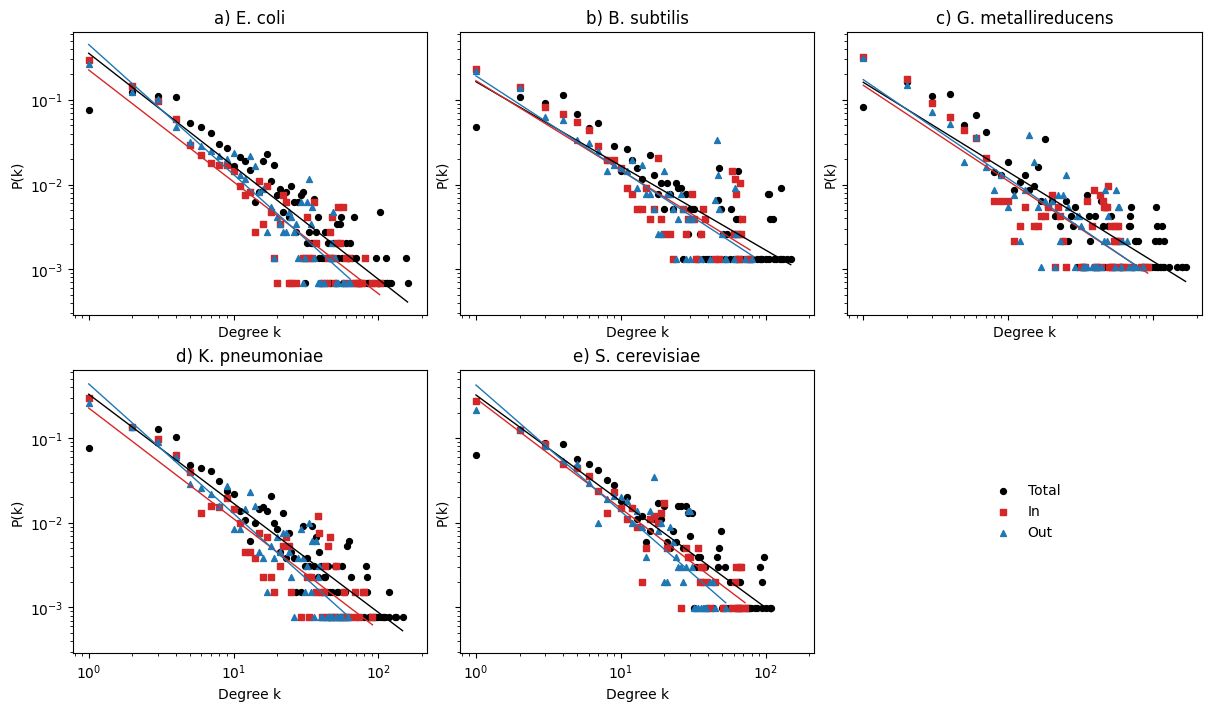

Our fit             Paper            
          Total    In   Out Total    In   Out
iJO1366   -1.33 -1.32 -1.54 -1.29 -1.32 -1.50
iYO844    -0.99 -1.06 -1.11 -1.03 -1.10 -1.12
iAF987    -1.06 -1.13 -1.17 -1.03 -1.14 -1.11
iYL1228   -1.29 -1.31 -1.53 -1.21 -1.31 -1.47
iMM904    -1.26 -1.30 -1.49 -0.99 -1.08 -1.16

In [5]:
# keep each model's exclusions and graph counts visible alongside the plots.
results = {models[0]: ecoli}
exclusions = {models[0]: ecoli_exclusions}
for model in models[1:]:
    reactions, species, exclusions[model] = read_reactions(
        data_dir / f"{model}.biggr.sbml.gz"
    )
    results[model] = build_degrees(reactions, species, currency_ids)

graph_counts = pd.DataFrame(index=models)
graph_counts["Nodes"] = [len(results[model]) for model in models]
graph_counts["Arcs"] = [results[model]["Out"].sum() for model in models]
display(pd.concat({"Our graph": graph_counts, "Paper": published_results[["Nodes", "Arcs"]]},
                  axis=1))
display(pd.DataFrame.from_dict(exclusions, orient="index").fillna(0).astype(int))

# Once E. coli checks out, I run the same plotting code for every model.
fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharex=True, sharey=True,
                         layout="constrained")
fits = {}
for index, model in enumerate(models):
    ax = axes.flat[index]
    fits[model] = plot_degrees(ax, results[model])
    ax.set_title(f"{chr(97 + index)}) {organisms[index]}")
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[5].axis("off")
axes.flat[5].legend(handles, labels, loc="center", frameon=False)
plt.show()

# compare the fitted slopes with Figure 2 at the same precision.
fitted_slopes = pd.DataFrame.from_dict(fits, orient="index")
display(pd.concat({"Our fit": fitted_slopes, "Paper": published_results[["Total", "In", "Out"]]},
                  axis=1).round(2))

## 4. Sensitivity to currency-metabolite filtering

We reran *E. coli* with currency metabolites allowed to create links. We kept the same reactions, directions, and fitting procedure. Compared the edge counts, typical degrees, and fitted slopes to see how much the figure depends on this choice.

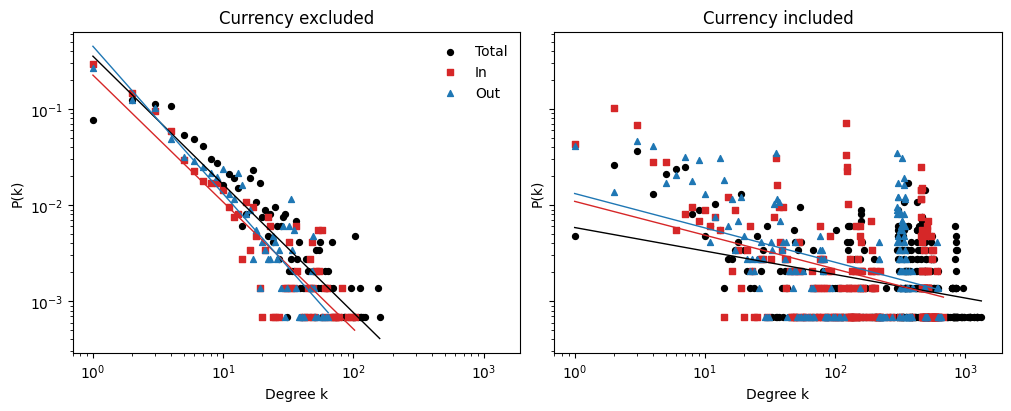

,Currency excluded,Currency included
Reactions,1467.00,1467.00
Arcs,8828.00,207659.00
Median total degree,5.00,305.00
Total slope,-1.33,-0.24
In slope,-1.32,-0.35
Out slope,-1.54,-0.36


In [6]:
# reuse the same reaction set, so only the allowed metabolite links change.
all_metabolite_degrees = build_degrees(ecoli_reactions, ecoli_species, set())
assert ecoli.index.equals(all_metabolite_degrees.index)
assert (all_metabolite_degrees >= ecoli).all().all()

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True,
                         layout="constrained")
comparison = {}
for ax, label, degrees in zip(
    axes, ["Currency excluded", "Currency included"], [ecoli, all_metabolite_degrees]
):
    slopes = plot_degrees(ax, degrees)
    ax.set_title(label)
    comparison[label] = {
        "Reactions": len(degrees),
        "Arcs": degrees["Out"].sum(),
        "Median total degree": degrees["Total"].median(),
        "Total slope": slopes["Total"],
        "In slope": slopes["In"],
        "Out slope": slopes["Out"],
    }
axes[0].legend(frameon=False)
plt.show()
display(pd.DataFrame(comparison).round(2))

## What we found in this run

The *E. coli* reconstruction matches the AACPS1 degree check and gives a similar total-degree slope (−1.33 versus −1.29), with different graph counts (1,467 reactions and 8,828 arcs versus 1,251 and 9,099). Yeast shows a larger difference in slopes. With the same *E. coli* reactions, allowing currency metabolites raises the median total degree from 5 to 305 and changes the fitted total-degree slope from −1.33 to −0.24. The graph construction has a large effect on the fitted result under these rules.